In [1]:
%load_ext autoreload
%autoreload 2

import time
from dataclasses import asdict

import pandas as pd

from fxml import config
from fxml.datasets.splits import walk_forward_splits
from fxml.datasets.table import build_table
from fxml.db.connection import connect
from fxml.db.repository import load_bars, save_run
from fxml.db.schema import init_db
from fxml.evaluation import plots
from fxml.evaluation.backtest import backtest, spread_cost
from fxml.training.experiment import Settings, run_walk_forward

plots.apply_style()
conn = connect()
init_db(conn)

HORIZON = 12
settings = Settings(horizon=HORIZON)
bars = load_bars(conn, "EURUSD", "H1", start=config.TRAIN_START)
table = build_table(bars, horizon=HORIZON)
folds = walk_forward_splits(len(table), train_size=31_000, test_size=3_100, gap=HORIZON)
print(len(table), "rows,", len(folds), "folds")


73339 rows, 13 folds


In [2]:
start = time.time()
wf = run_walk_forward(table, folds, settings)
print(f"done in {(time.time() - start) / 60:.1f} min")


fold 1/13: accuracy 0.533 (guess 0.510), rank corr +0.098, best epoch 1
fold 2/13: accuracy 0.530 (guess 0.428), rank corr -0.008, best epoch 2
fold 3/13: accuracy 0.490 (guess 0.519), rank corr +0.034, best epoch 3
fold 4/13: accuracy 0.539 (guess 0.471), rank corr -0.008, best epoch 3
fold 5/13: accuracy 0.511 (guess 0.461), rank corr -0.006, best epoch 2
fold 6/13: accuracy 0.502 (guess 0.510), rank corr +0.018, best epoch 2
fold 7/13: accuracy 0.535 (guess 0.478), rank corr +0.055, best epoch 1
fold 8/13: accuracy 0.509 (guess 0.494), rank corr +0.018, best epoch 1
fold 9/13: accuracy 0.533 (guess 0.498), rank corr +0.105, best epoch 3
fold 10/13: accuracy 0.541 (guess 0.501), rank corr +0.070, best epoch 3
fold 11/13: accuracy 0.496 (guess 0.477), rank corr -0.045, best epoch 6
fold 12/13: accuracy 0.514 (guess 0.493), rank corr +0.054, best epoch 2
fold 13/13: accuracy 0.500 (guess 0.444), rank corr -0.005, best epoch 2
done in 2.1 min


In [3]:
preds = wf.predictions
threshold = (preds["prob_up"] - 0.5).abs().quantile(0.8)
cost = spread_cost(bars, config.POINT_SIZE)
bt = backtest(preds, cost, threshold, HORIZON)
slip = backtest(preds, cost, threshold, HORIZON, extra_cost_bps=0.3)

m = wf.metrics
summary = {**bt.stats, "net_bps_with_0.3_slippage": slip.stats["net_bps_per_trade"],
           "mean_accuracy": m["test_direction_accuracy"].mean(),
           "mean_rank_corr": m["test_rank_corr"].mean(),
           "folds_positive_rank_corr": int((m["test_rank_corr"] > 0).sum()),
           "n_folds": len(folds)}
save_run(conn, "confirm-h12", "EURUSD", "H1", asdict(settings), m, summary=summary,
         notes="CONFIRMATION 2015-2026, recorded spread, top-20% rule, run once")

print(f"net Sharpe                 {bt.stats['sharpe']:+.2f}   (need > 0.5)")
print(f"net bps/trade w/ 0.3 slip  {slip.stats['net_bps_per_trade']:+.2f}   (need >= +0.5)")
print(f"gross / net bps per trade  {bt.stats['gross_bps_per_trade']:+.2f} / {bt.stats['net_bps_per_trade']:+.2f}")
print(f"rank corr {summary['mean_rank_corr']:+.3f}, positive in {summary['folds_positive_rank_corr']}/{len(folds)} folds")
print(f"max drawdown {bt.stats['max_drawdown']:.1%}, total return {bt.stats['total_return']:.1%}")


net Sharpe                 +0.33   (need > 0.5)
net bps/trade w/ 0.3 slip  +0.04   (need >= +0.5)
gross / net bps per trade  +1.02 / +0.34
rank corr +0.029, positive in 8/13 folds
max drawdown -7.0%, total return 2.3%


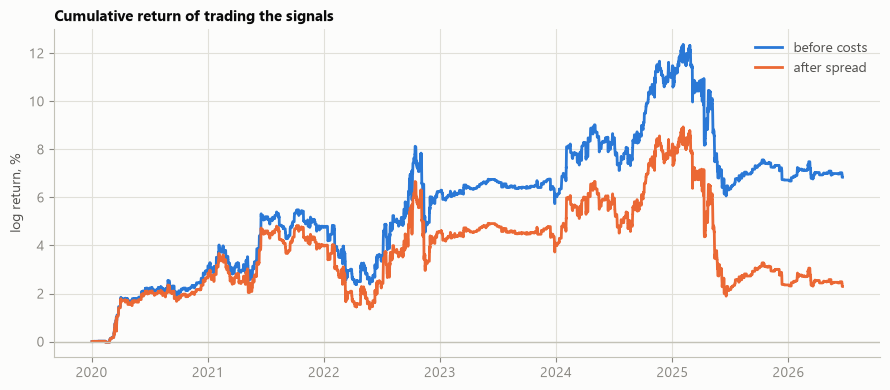

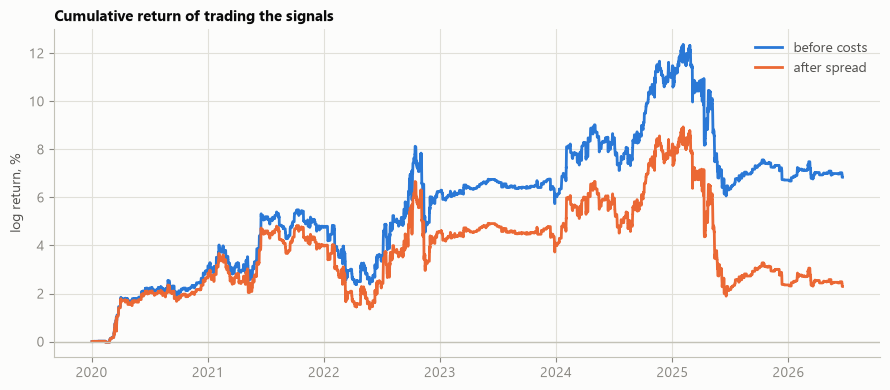

In [4]:
plots.equity_curve(bt.gross_equity, bt.equity)


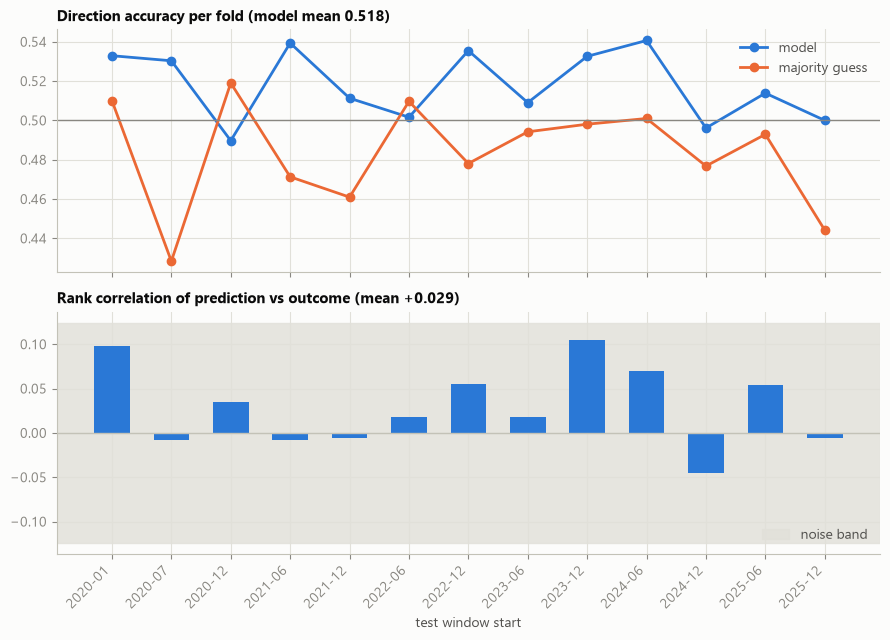

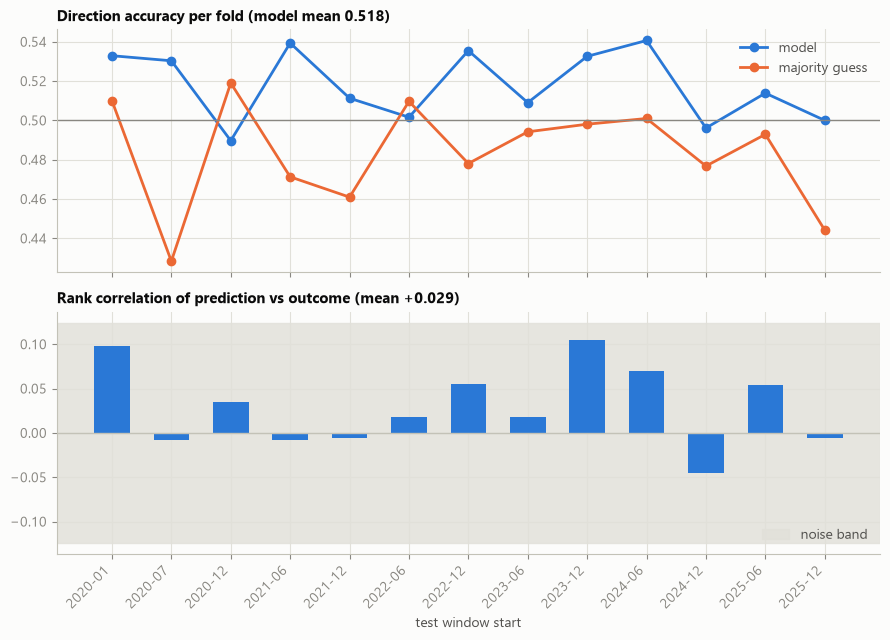

In [5]:
plots.fold_results(wf.metrics, horizon=HORIZON)
